Task 4: High-Imbalance Clinical Disease Predictor Pipeline

Objective

The objective of this project is to develop a machine learning classification pipeline that identifies malignant and benign breast cancer cases using diagnostic measurements.

The project demonstrates data exploration, preprocessing, class imbalance handling, model training, hyperparameter tuning, cross-validation and evaluation using recall and other classification metrics.

This is an educational machine learning project and is not intended to replace professional medical diagnosis.

In [1]:
%pip install -q imbalanced-learn xgboost

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
import xgboost

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

random_state = 42
np.random.seed(random_state)

os.makedirs("images", exist_ok=True)

print("Scikit-Learn:", sklearn.__version__)
print("Imbalanced-Learn:", imblearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Libraries imported successfully!")

Scikit-Learn: 1.6.1
Imbalanced-Learn: 0.14.2
XGBoost: 3.4.1
Libraries imported successfully!


In [3]:
data = load_breast_cancer(as_frame=True)

X = data.data.copy()

# Original labels: 0 = malignant, 1 = benign.
# Convert the target so 1 means malignant (the positive class).
y = (data.target == 0).astype(int)

print("Dataset loaded successfully!")
print("Number of records:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target labels:", np.unique(y))
print("Target meaning: 1 = Malignant, 0 = Benign")

Dataset loaded successfully!
Number of records: 569
Number of features: 30
Target labels: [0 1]
Target meaning: 1 = Malignant, 0 = Benign


In [4]:
print("First five rows:")
display(X.head())

print("\nDataset information:")
X.info()

print("\nStatistical summary:")
display(X.describe().T.head(10))

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744



Missing values:
0

Target distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


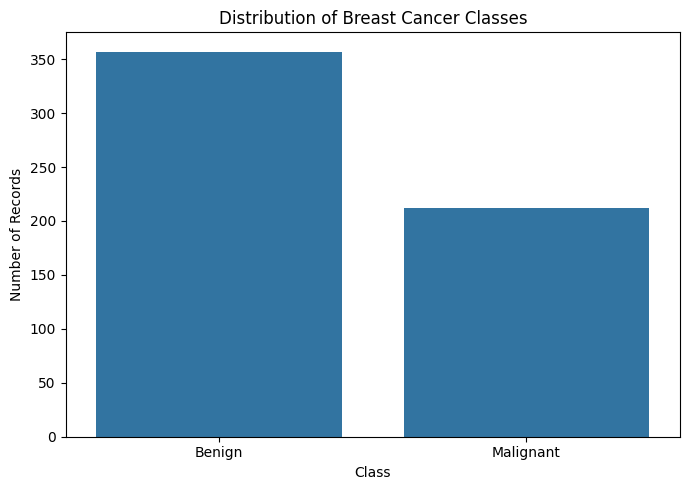

Class proportions:
target
Benign       0.627
Malignant    0.373
Name: proportion, dtype: float64


In [5]:
class_counts = y.map({
    0: "Benign",
    1: "Malignant"
}).value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig("images/class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Class proportions:")
print(y.value_counts(normalize=True).rename(index={
    0: "Benign",
    1: "Malignant"
}).round(3))

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training records: 455
Testing records: 114

Training class distribution:
target
0    285
1    170
Name: count, dtype: int64

Testing class distribution:
target
0    72
1    42
Name: count, dtype: int64


In [7]:
print("Training class counts before SMOTE:")
print(y_train.value_counts().sort_index())

smote_demo = SMOTE(random_state=42)

X_resampled, y_resampled = smote_demo.fit_resample(
    X_train,
    y_train
)

print("\nTraining class counts after SMOTE:")
print(pd.Series(y_resampled).value_counts().sort_index())

Training class counts before SMOTE:
target
0    285
1    170
Name: count, dtype: int64

Training class counts after SMOTE:
target
0    285
1    285
Name: count, dtype: int64


In [8]:
models_and_grids = {
    "SVM": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("smote", SMOTE(random_state=42)),
            ("classifier", SVC(
                probability=True,
                random_state=42
            ))
        ]),
        "params": {
            "classifier__C": [0.1, 1, 10],
            "classifier__kernel": ["linear", "rbf"],
            "classifier__class_weight": [None, "balanced"]
        }
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("smote", SMOTE(random_state=42)),
            ("classifier", RandomForestClassifier(
                random_state=42,
                n_jobs=1
            ))
        ]),
        "params": {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [None, 10],
            "classifier__class_weight": [None, "balanced"]
        }
    },

    "XGBoost": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("smote", SMOTE(random_state=42)),
            ("classifier", XGBClassifier(
                random_state=42,
                eval_metric="logloss",
                n_jobs=1
            ))
        ]),
        "params": {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [3, 5],
            "classifier__learning_rate": [0.05, 0.1]
        }
    }
}

print("Three model pipelines and parameter grids are ready.")

Three model pipelines and parameter grids are ready.


In [9]:
search_results = {}
comparison_rows = []

for model_name, config in models_and_grids.items():
    print(f"\nTuning {model_name}...")

    search = GridSearchCV(
        estimator=config["pipeline"],
        param_grid=config["params"],
        scoring="recall",
        cv=5,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )

    search.fit(X_train, y_train)

    search_results[model_name] = search

    # Find the cross-validation results for the best parameter combination
    best_index = search.best_index_

    fold_recalls = [
        search.cv_results_[f"split{i}_test_score"][best_index]
        for i in range(5)
    ]

    # Evaluate on the separate test set
    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    row = {
        "Model": model_name,
        "Best CV Recall": search.best_score_,
        "CV Recall Std": search.cv_results_["std_test_score"][best_index],
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(y_test, y_pred, zero_division=0),
        "Test Recall": recall_score(y_test, y_pred, zero_division=0),
        "Test F1": f1_score(y_test, y_pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob),
        "Best Parameters": search.best_params_
    }

    comparison_rows.append(row)

    print("Best parameters:", search.best_params_)
    print("Five fold recall scores:", np.round(fold_recalls, 4))
    print(f"Mean CV recall: {search.best_score_:.4f}")
    print(f"Test recall: {row['Test Recall']:.4f}")

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.drop(columns=["Best Parameters"])
    .sort_values("Best CV Recall", ascending=False)
    .round(4)
)


Tuning SVM...
Best parameters: {'classifier__C': 10, 'classifier__class_weight': None, 'classifier__kernel': 'rbf'}
Five fold recall scores: [0.9412 1.     0.9118 1.     0.9412]
Mean CV recall: 0.9588
Test recall: 0.9524

Tuning Random Forest...
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__n_estimators': 200}
Five fold recall scores: [1.     0.9706 0.8824 0.9706 0.9118]
Mean CV recall: 0.9471
Test recall: 0.9286

Tuning XGBoost...
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 200}
Five fold recall scores: [0.9706 1.     0.9118 0.9706 0.9412]
Mean CV recall: 0.9588
Test recall: 0.9048


,Model,Best CV Recall,CV Recall Std,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,SVM,0.9588,0.0353,0.9825,1.0,0.9524,0.9756,0.9934
2,XGBoost,0.9588,0.0300,0.9649,1.0,0.9048,0.9500,0.9931
1,Random Forest,0.9471,0.0432,0.9737,1.0,0.9286,0.9630,0.9960


In [10]:
best_model_name = comparison_df.loc[
    comparison_df["Best CV Recall"].idxmax(),
    "Model"
]

best_search = search_results[best_model_name]
best_model = best_search.best_estimator_

print("Selected model:", best_model_name)
print("Best cross-validation recall:", round(best_search.best_score_, 4))
print("Best parameters:", best_search.best_params_)

Selected model: SVM
Best cross-validation recall: 0.9588
Best parameters: {'classifier__C': 10, 'classifier__class_weight': None, 'classifier__kernel': 'rbf'}


In [11]:
y_pred_best = best_model.predict(X_test)
y_prob_best = best_model.predict_proba(X_test)[:, 1]

final_accuracy = accuracy_score(y_test, y_pred_best)
final_precision = precision_score(y_test, y_pred_best, zero_division=0)
final_recall = recall_score(y_test, y_pred_best, zero_division=0)
final_f1 = f1_score(y_test, y_pred_best, zero_division=0)
final_roc_auc = roc_auc_score(y_test, y_prob_best)

print("FINAL MODEL:", best_model_name)
print("-" * 40)
print(f"Test Accuracy:  {final_accuracy:.4f}")
print(f"Test Precision: {final_precision:.4f}")
print(f"Test Recall:    {final_recall:.4f}")
print(f"Test F1-score:  {final_f1:.4f}")
print(f"Test ROC-AUC:   {final_roc_auc:.4f}")

FINAL MODEL: SVM
----------------------------------------
Test Accuracy:  0.9825
Test Precision: 1.0000
Test Recall:    0.9524
Test F1-score:  0.9756
Test ROC-AUC:   0.9934


In [12]:
final_report = classification_report(
    y_test,
    y_pred_best,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
)

print(final_report)

with open("classification_report.txt", "w") as file:
    file.write(final_report)

              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



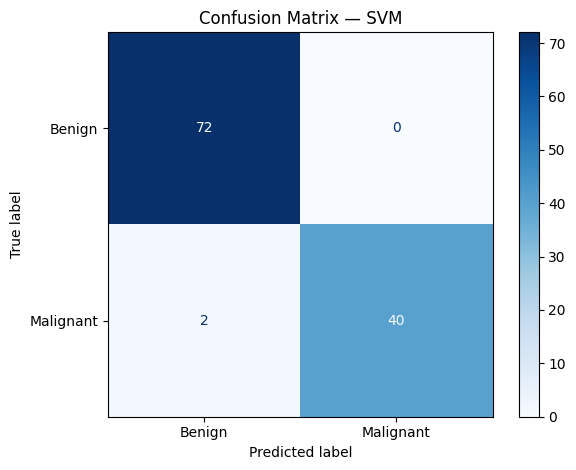

In [13]:
cm = confusion_matrix(y_test, y_pred_best, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()

plt.savefig(
    "images/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

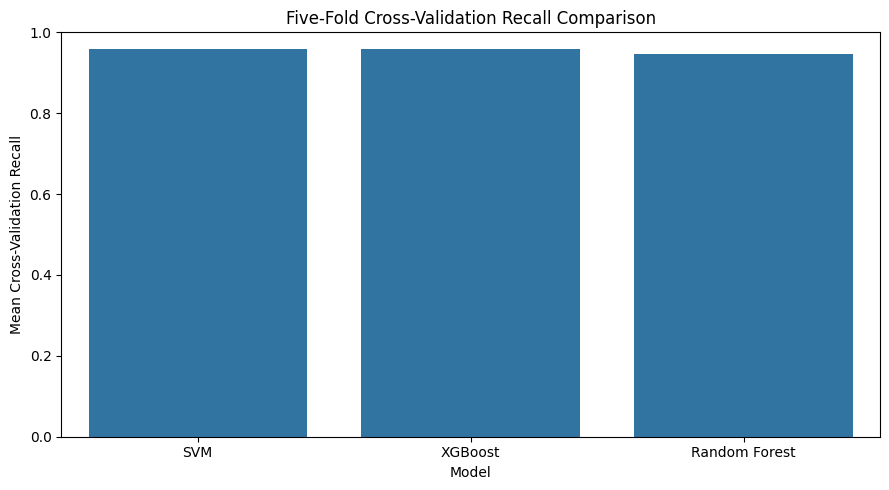

In [14]:
plot_df = comparison_df.sort_values("Best CV Recall", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=plot_df,
    x="Model",
    y="Best CV Recall"
)

plt.ylim(0, 1)
plt.title("Five-Fold Cross-Validation Recall Comparison")
plt.ylabel("Mean Cross-Validation Recall")
plt.xlabel("Model")
plt.tight_layout()

plt.savefig(
    "images/cv_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

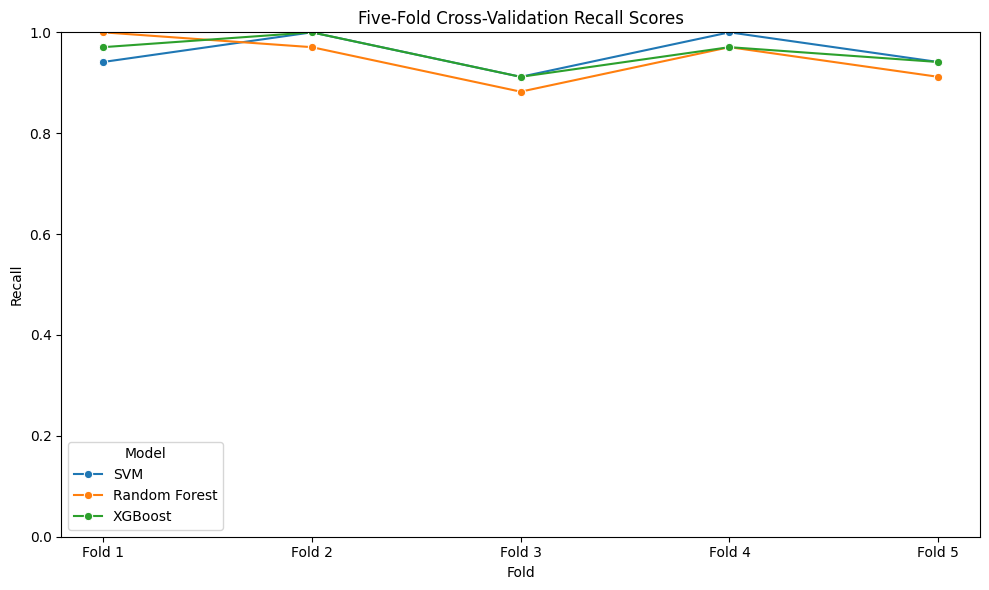

Model,Random Forest,SVM,XGBoost
Fold,,,
Fold 1,1.0000,0.9412,0.9706
Fold 2,0.9706,1.0000,1.0000
Fold 3,0.8824,0.9118,0.9118
Fold 4,0.9706,1.0000,0.9706
Fold 5,0.9118,0.9412,0.9412


In [15]:
fold_rows = []

for model_name, search in search_results.items():
    best_index = search.best_index_

    for fold in range(5):
        fold_rows.append({
            "Model": model_name,
            "Fold": f"Fold {fold + 1}",
            "Recall": search.cv_results_[
                f"split{fold}_test_score"
            ][best_index]
        })

fold_df = pd.DataFrame(fold_rows)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=fold_df,
    x="Fold",
    y="Recall",
    hue="Model",
    marker="o"
)

plt.ylim(0, 1)
plt.title("Five-Fold Cross-Validation Recall Scores")
plt.ylabel("Recall")
plt.tight_layout()

plt.savefig(
    "images/cv_fold_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(fold_df.pivot(
    index="Fold",
    columns="Model",
    values="Recall"
).round(4))

In [16]:
comparison_df.to_csv("model_comparison.csv", index=False)
fold_df.to_csv("cross_validation_recall.csv", index=False)

print("Model comparison and cross-validation results saved.")

Model comparison and cross-validation results saved.


In [17]:
import joblib

joblib.dump(best_model, "best_clinical_predictor.joblib")

print("Best model saved:", best_model_name)
print("Model file: best_clinical_predictor.joblib")

Best model saved: SVM
Model file: best_clinical_predictor.joblib


In [18]:
summary = f"""
Task 4: Clinical Disease Predictor

Dataset: Wisconsin Breast Cancer Diagnostic dataset
Positive class: Malignant
Selected model: {best_model_name}

Test Accuracy: {final_accuracy:.4f}
Test Precision: {final_precision:.4f}
Test Recall: {final_recall:.4f}
Test F1-score: {final_f1:.4f}
Test ROC-AUC: {final_roc_auc:.4f}

Best hyperparameters:
{best_search.best_params_}

Mean five-fold CV recall:
{best_search.best_score_:.4f}
"""

print(summary)

with open("results_summary.txt", "w") as file:
    file.write(summary)


Task 4: Clinical Disease Predictor

Dataset: Wisconsin Breast Cancer Diagnostic dataset
Positive class: Malignant
Selected model: SVM

Test Accuracy: 0.9825
Test Precision: 1.0000
Test Recall: 0.9524
Test F1-score: 0.9756
Test ROC-AUC: 0.9934

Best hyperparameters:
{'classifier__C': 10, 'classifier__class_weight': None, 'classifier__kernel': 'rbf'}

Mean five-fold CV recall:
0.9588

